# V1DD UMAP embedding features

Reads `v1dd_qc_nonnull_stable_v1512.parquet` from the V1DD 1512 UMAP release and writes
the two UMAP coordinates per cell as a CCM cell feature set.

In [1]:
from pathlib import Path

import polars as pl
import pyarrow as pa
from deltalake import write_deltalake

from connects_common_connectivity.config import get_settings
from connects_common_connectivity.io import write_models
from connects_common_connectivity.io.arrow_utils import build_cell_feature_matrix_schema
from connects_common_connectivity.models import CellFeatureDefinition, CellFeatureMatrix, CellFeatureSet, Unit

In [2]:
DATA_ROOT = Path("/data/v1dd_1512_umap")
UMAP_PATH = DATA_ROOT / "v1dd_qc_nonnull_stable_v1512.parquet"

In [3]:
umap = pl.read_parquet(UMAP_PATH)
print(umap.shape)
print(umap.schema)

(54832, 4)
Schema({'cell_id': Int64, 'root_id': UInt64, 'umap_stable0': Float32, 'umap_stable1': Float32})


In [4]:
umap.head()

cell_id,root_id,umap_stable0,umap_stable1
i64,u64,f32,f32
203262,864691132654552792,-1.392867,13.206879
350562,864691132685437664,-0.179063,12.864546
367611,864691132718985293,0.318835,7.944404
29289,864691132997081013,-1.052074,13.331438
525091,864691132645534518,1.634117,4.493191


## Data validation cleanup

In [5]:
OUTPUT_ROOT = get_settings().output_root
PROJECT_ID = "v1dd"
DENDRITE_DATASET_ID = "v1dd_1196_em"
FEATURE_SET_ID = "v1dd_1512_umap"

In [6]:
assoc = (
    pl.read_delta(OUTPUT_ROOT / "dataitem_dataset_association")
    .filter((pl.col("project_id") == PROJECT_ID) & (pl.col("dataset_id") == DENDRITE_DATASET_ID))
)
assert assoc.shape[0] > 0, f"No DataItems found for {DENDRITE_DATASET_ID}."

dendrite_ids = set(assoc["dataitem_id"].to_list())
umap_cc = (
    umap
    .rename({"umap_stable0": "umap_x", "umap_stable1": "umap_y"})
    .with_columns(pl.col("root_id").cast(pl.Utf8).alias("id"))
    .filter(pl.col("id").is_not_null())
    .filter(pl.col("umap_x").is_not_null() & pl.col("umap_y").is_not_null())
    .filter(pl.col("id").is_in(list(dendrite_ids)))
    .unique(subset=["id"], keep="first")
)

assert umap_cc.height > 0, "No UMAP rows remained after dataset filter."
assert set(umap_cc["id"].to_list()).issubset(dendrite_ids)

print(f"registered rootids: {len(dendrite_ids)}")
print(f"umap rows kept: {umap_cc.height} of {umap.height}")

registered rootids: 143448
umap rows kept: 11851 of 54832


## Write the features

In [7]:
FEATURE_COLUMNS = ["umap_x", "umap_y"]

DESCRIPTION_BY_FEATURE = {
    "umap_x": "Stable UMAP embedding x coordinate (source column umap_stable0).",
    "umap_y": "Stable UMAP embedding y coordinate (source column umap_stable1).",
}

feature_defs = [
    CellFeatureDefinition(
        id=col,
        description=DESCRIPTION_BY_FEATURE[col],
        unit=Unit.ARBITRARY_UNIT.value,
        data_type="<f8",
        project_id=PROJECT_ID,
        feature_set_id=FEATURE_SET_ID,
    )
    for col in FEATURE_COLUMNS
]
write_models(feature_defs, output_root=OUTPUT_ROOT)

WrittenResult(class_name='CellFeatureDefinition', path=PosixPath('/scratch/v1dd_ccm_20260908/cellfeaturedefinition'), mode='overwrite_scoped', predicates=("project_id = 'v1dd' AND feature_set_id = 'v1dd_umap'",), rows_written=2)

In [8]:
feature_set = CellFeatureSet(
    id=FEATURE_SET_ID,
    description="V1DD stable UMAP embedding coordinates per cell.",
    feature_definition_ids=[fd.id for fd in feature_defs],
    extraction_method="Loaded from v1dd_1512_umap v1dd_qc_nonnull_stable_v1512.parquet.",
    project_id=PROJECT_ID,
)
write_models([feature_set], output_root=OUTPUT_ROOT)

WrittenResult(class_name='CellFeatureSet', path=PosixPath('/scratch/v1dd_ccm_20260908/cellfeatureset'), mode='overwrite_scoped', predicates=("project_id = 'v1dd' AND id = 'v1dd_umap'",), rows_written=1)

In [9]:
wide_df = (
    umap_cc
    .select(["id"] + FEATURE_COLUMNS)
    .with_columns([pl.col(c).cast(pl.Float64) for c in FEATURE_COLUMNS])
    .to_pandas()
)
wide_df["project_id"] = PROJECT_ID
wide_df["feature_set_id"] = FEATURE_SET_ID

schema_wide = build_cell_feature_matrix_schema(feature_set, feature_defs, cell_index_column="id")
table_wide = pa.Table.from_pandas(wide_df, schema=schema_wide, preserve_index=False)
write_deltalake(
    OUTPUT_ROOT / f"cellfeatures/{FEATURE_SET_ID}",
    table_wide,
    mode="overwrite",
    predicate=f"project_id = '{PROJECT_ID}'",
    partition_by=["project_id", "feature_set_id"],
    # allow re-runs after a feature column is renamed/added
    schema_mode="overwrite",
)

cfm = CellFeatureMatrix(
    id=f"{PROJECT_ID}_{FEATURE_SET_ID}",
    feature_set_id=FEATURE_SET_ID,
    parquet_path=f"file://{OUTPUT_ROOT.resolve()}/cellfeatures/{FEATURE_SET_ID}/",
    cell_index_column="id",
    project_id=PROJECT_ID,
)
write_models([cfm], output_root=OUTPUT_ROOT)

WrittenResult(class_name='CellFeatureMatrix', path=PosixPath('/scratch/v1dd_ccm_20260908/cellfeaturematrix'), mode='overwrite_scoped', predicates=("project_id = 'v1dd' AND feature_set_id = 'v1dd_umap'",), rows_written=1)

In [10]:
print(f"wrote {len(feature_defs)} feature definitions")
print(f"wrote wide feature matrix rows: {table_wide.num_rows}")

wrote 2 feature definitions
wrote wide feature matrix rows: 11851


## Plot the UMAP colored by cell type

Colors come from the `hex_color` column of the `Cluster` rows for the
`v1dd_cell_types` hierarchy (populated by `etl_v1dd_04_cellTypeColors.ipynb`).
Cells are assigned to their fine (leaf) cell type via `ClusterMembership`;
clusters without a color are drawn in gray.

In [11]:
import matplotlib.pyplot as plt

HIERARCHY_ID = "v1dd_cell_types"
FALLBACK_COLOR = "#c8c8c8"

clusters = (
    pl.read_delta(OUTPUT_ROOT / "cluster")
    .filter(pl.col("hierarchy_id") == HIERARCHY_ID)
)
memberships = (
    pl.read_delta(OUTPUT_ROOT / "clustermembership")
    .filter((pl.col("project_id") == PROJECT_ID) & (pl.col("hierarchy_id") == HIERARCHY_ID))
)

# Leaf clusters are the fine cell types; coarse ones (neuron, E, I) have children.
leaf_ids = (
    clusters
    .filter(pl.col("children").is_null() | (pl.col("children").list.len() == 0))
    ["id"].to_list()
)
coarse_ids = ["E", "I"]

color_by_cluster = dict(zip(clusters["id"].to_list(), clusters["hex_color"].to_list()))
n_missing_color = sum(color_by_cluster.get(c) is None for c in leaf_ids)
if n_missing_color:
    print(f"\u26a0\ufe0f  {n_missing_color}/{len(leaf_ids)} leaf clusters have no hex_color; "
          "run etl_v1dd_04_cellTypeColors.ipynb to populate them.")

print(f"leaf cell types: {sorted(leaf_ids)}")
print(f"cluster memberships: {memberships.height}")

leaf cell types: ['DTC', 'ITC', 'L2-IT', 'L3-IT', 'L4-IT', 'L5-ET', 'L5-IT', 'L5-NP', 'L6-CT', 'L6-IT', 'PTC', 'STC']
cluster memberships: 147576


In [12]:
def umap_with_clusters(cluster_ids):
    """UMAP coordinates joined to a one-cluster-per-cell membership subset."""
    sub = (
        memberships
        .filter(pl.col("cluster").is_in(cluster_ids))
        .select(pl.col("item").alias("id"), pl.col("cluster"))
        .unique(subset=["id"], keep="first")
    )
    return umap_cc.select(["id"] + FEATURE_COLUMNS).join(sub, on="id", how="inner")


def plot_umap(df, title, ax, point_size=2.0):
    """Scatter the UMAP, one color per cluster, largest groups drawn first."""
    order = (
        df.group_by("cluster").len().sort("len", descending=True)["cluster"].to_list()
    )
    for cluster_id in order:
        grp = df.filter(pl.col("cluster") == cluster_id)
        ax.scatter(
            grp[FEATURE_COLUMNS[0]].to_numpy(),
            grp[FEATURE_COLUMNS[1]].to_numpy(),
            s=point_size,
            linewidths=0,
            color=color_by_cluster.get(cluster_id) or FALLBACK_COLOR,
            label=f"{cluster_id} (n={grp.height})",
        )
    ax.set_xlabel(FEATURE_COLUMNS[0])
    ax.set_ylabel(FEATURE_COLUMNS[1])
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.legend(markerscale=6, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
    return ax

cells with a fine cell type  : 9276 of 11851
cells with a coarse E/I label: 9276 of 11851


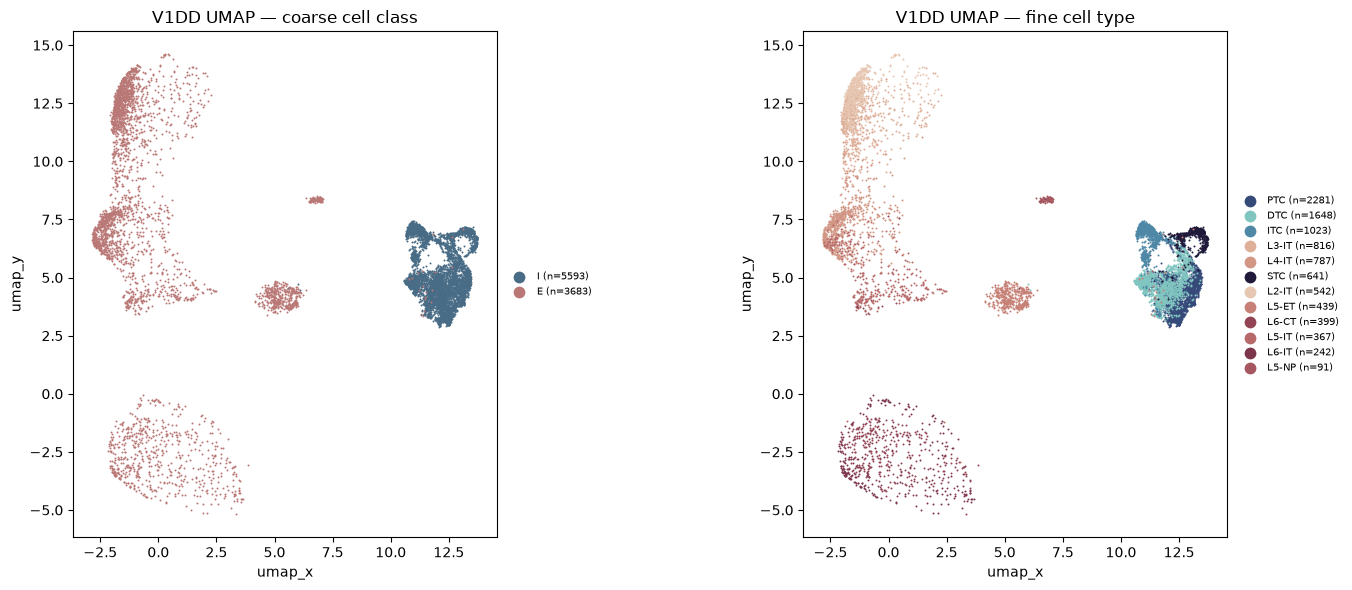

In [13]:
fine_df = umap_with_clusters(leaf_ids)
coarse_df = umap_with_clusters(coarse_ids)
print(f"cells with a fine cell type  : {fine_df.height} of {umap_cc.height}")
print(f"cells with a coarse E/I label: {coarse_df.height} of {umap_cc.height}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_umap(coarse_df, "V1DD UMAP — coarse cell class", axes[0])
plot_umap(fine_df, "V1DD UMAP — fine cell type", axes[1])
fig.tight_layout()
plt.show()